# code_185 · Family screening and architecture choices are linked

**Book:** section 35.3. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution is offline and CPU-only after explicit acquisition of the hash-verified public TabPFN v 2 checkpoint; see [assets](../CHAPTER_35_ASSETS.md). No credentials are required. Built with PriorLabs-TabPFN. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_35_GUIDE.md), [execution evidence](../CHAPTER_35_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_185).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Configuration spaces, data roles, selection information and resource accounting are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7685;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7685


<a id="screen-families-before-tuning"></a>
 ## Spend a declared screening stage before expanding a family
 Generate 64 independent buildings with five observations each:32 source/16 development/16 final. The visible four-feature task has nonlinear severity/load effects and unobserved building variation. Screen one fixed recipe each: median-imputed/scaled logistic regression, a 60-tree histogram booster, a 4→8→1 Tanh classifier with 200 source updates, and native TabPFN v 2 with one ensemble member. TabPFN receives the same 160 labelled source rows as context; it does not receive final labels. Its public pretraining history is additional upstream computation, so this is not a claim of equal lifetime compute.

 Verify the exact 29,009,539-byte public checkpoint before loading. Use the explicit [acquisition guide](../CHAPTER_35_ASSETS.md) and `python scripts/acquire_chapter35_model.py` once; notebook execution sets offline mode and fails if verified weights are absent. No runtime download or fabricated substitute is permitted. The cached v 2 network is selected explicitly, not the installed library's newer default. An eight-row source-feature prediction prepares native inference precision before network-parameter hashes are recorded; this preparation uses no development or final labels. Hashes then test unchanged parameters across assessment predictions, not immutability of every wrapper state.


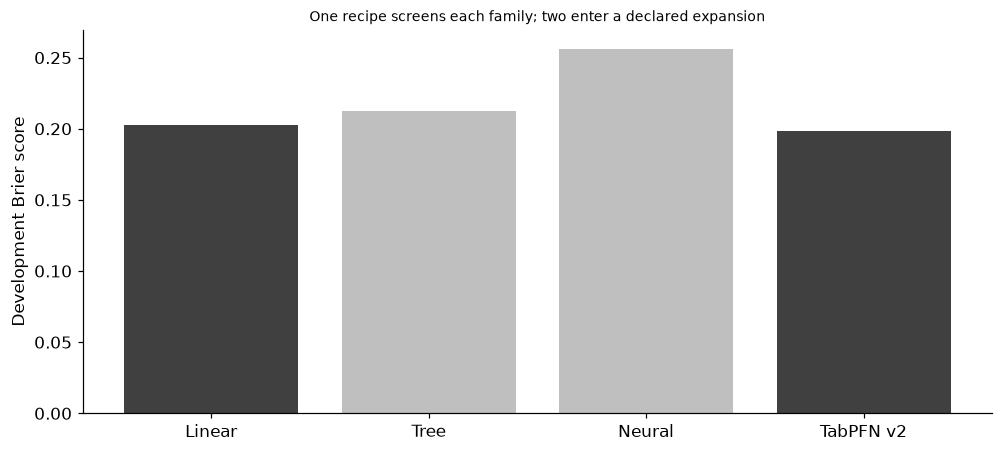

In [2]:
import os,importlib.metadata as metadata
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1'
from tabpfn import TabPFNClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss,log_loss
VERSIONS['tabpfn']=metadata.version('tabpfn');VERSIONS['huggingface-hub']=metadata.version('huggingface-hub')
roots=[Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'];ROOT=next(p for p in roots if (p/'examples.json').is_file());revision='f851f2a3c941544733b712d8c0f96dfae9b28862';filename='tabpfn-v2-classifier-v2_default.ckpt';checkpoint=ROOT/'build/model-cache/models--Prior-Labs--TabPFN-v2-clf/snapshots'/revision/filename;expected_hash='cf8c519c01eaf1613ee91239006d57b1c806ff5f23ac1aeb1315ba1015210e49';assert checkpoint.is_file(),'Run python scripts/acquire_chapter35_model.py explicitly; see CHAPTER_35_ASSETS.md';blob=checkpoint.read_bytes();assert len(blob)==29009539 and hashlib.sha256(blob).hexdigest()==expected_hash;del blob
group=np.repeat(np.arange(64),5);X=rng.normal(size=(320,4));X[:,:2]+=rng.normal(scale=.6,size=(64,2))[group];latent=.9*np.sin(X[:,0])-.8*X[:,1]+.7*X[:,2]*X[:,3]+rng.normal(scale=.3,size=64)[group];prob=1/(1+np.exp(-latent));Y=(rng.random(320)<prob).astype(int);X[rng.random(X.shape)<.04]=np.nan;source=group<32;development=(group>=32)&(group<48);final=group>=48;rows=[];models={};dev_predictions={};foundation_hashes=[]
def weights_hash(m):return hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for module in m.models_ for p in module.parameters())).hexdigest()
def fit_family(family,expanded=False):
    if family=='Linear':
        steps=[SimpleImputer(strategy='median')]+([PolynomialFeatures(2,include_bias=False)] if expanded else [])+[StandardScaler(),LogisticRegression(C=.1 if expanded else 1.,max_iter=500)];m=make_pipeline(*steps).fit(X[source],Y[source]);return lambda x:m.predict_proba(x)[:,1],{'representation':'quadratic interactions' if expanded else 'raw four fields','C':.1 if expanded else 1.}
    if family=='Tree':
        m=HistGradientBoostingClassifier(max_iter=100 if expanded else 60,max_leaf_nodes=15 if expanded else 7,learning_rate=.05 if expanded else .08,min_samples_leaf=12,early_stopping=False,random_state=SEED).fit(X[source],Y[source]);return lambda x:m.predict_proba(x)[:,1],{'trees':int(m.n_iter_),'leaves':15 if expanded else 7}
    if family=='Neural':
        imp=SimpleImputer(strategy='median').fit(X[source]);scaler=StandardScaler().fit(imp.transform(X[source]));torch.manual_seed(SEED);m=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,8),nn.Tanh(),nn.Linear(8,1)) if expanded else nn.Sequential(nn.Linear(4,8),nn.Tanh(),nn.Linear(8,1));opt=torch.optim.Adam(m.parameters(),lr=.01,weight_decay=.001);z=torch.tensor(scaler.transform(imp.transform(X[source])));y=torch.tensor(Y[source],dtype=torch.float64)
        for _ in range(200):loss=nn.functional.binary_cross_entropy_with_logits(m(z).squeeze(1),y);opt.zero_grad();loss.backward();opt.step()
        def predict(x):
            with torch.no_grad():return torch.sigmoid(m(torch.tensor(scaler.transform(imp.transform(x)))).squeeze(1)).numpy()
        return predict,{'architecture':[4,16,8,1] if expanded else [4,8,1],'weights':sum(p.numel() for p in m.parameters()),'updates':200}
    m=TabPFNClassifier(n_estimators=4 if expanded else 1,model_path=checkpoint,device='cpu',inference_precision=torch.float32,n_preprocessing_jobs=1,random_state=SEED);m.fit(X[source],Y[source]);m.predict_proba(X[source][:8]);before=weights_hash(m)
    def predict(x):
        p=m.predict_proba(x)[:,1];assert weights_hash(m)==before;return p
    foundation_hashes.append(before);return predict,{'ensemble_members':int(m.n_estimators_),'checkpoint_sha256':expected_hash,'pretrained_parameters':sum(p.numel() for module in m.models_ for p in module.parameters()),'gradient_updates':0}
for family in ['Linear','Tree','Neural','TabPFN v2']:
    predict,detail=fit_family(family);p=predict(X[development]);name=family+' screen';models[name]=predict;dev_predictions[name]=p;rows.append({'candidate':name,'family':family,'stage':'screen','development_Brier':float(brier_score_loss(Y[development],p)),'configuration':detail})
shortlist=[r['family'] for r in sorted(rows,key=lambda r:r['development_Brier'])[:2]];assert len(set(shortlist))==2 and len(rows)==4;assert set(group[source]).isdisjoint(set(group[development])|set(group[final]))
RESULTS.update(building_roles=[32,16,16],records_per_building=5,checkpoint_repository='Prior-Labs/TabPFN-v2-clf',checkpoint_revision=revision,checkpoint_filename=filename,checkpoint_sha256=expected_hash,checkpoint_bytes=29009539,shortlisted_families=shortlist,screen_candidates=copy.deepcopy(rows),upstream_pretraining_compute_equal=False)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(range(4),[r['development_Brier'] for r in rows],color=['.25' if r['family'] in shortlist else '.75' for r in rows]);ax.set(xticks=range(4),xticklabels=[r['family'] for r in rows],ylabel='Development Brier score',title='One recipe screens each family; two enter a declared expansion');plt.show()


<a id="shortlist-architecture-and-ensemble"></a>
 ## Expand only the shortlisted families and retain the full attempt record
 Each shortlisted family has one predeclared expansion: quadratic features plus stronger regularization for linear fitting; more leaves/trees with a lower rate for boosting; a second hidden layer for the neural model; or four context-ensemble members for the fixed foundation checkpoint. These are linked representation, architecture and recipe choices. Changing neural wiring is architecture search; changing only its step size would be ordinary training-parameter tuning. No unrestricted NAS or benchmark result is claimed.

 Choose the lowest development Brier among all six attempts. Also form a convex probability ensemble of the two best development candidates, fitting its one weight by least squares on those development labels. This spends additional development information, which stays visible in the log. Lock both recipes before scoring final outcomes. Compare selected single, fitted ensemble and source-prevalence reference on the same 80 final records; do not select an ensemble weight or family from final performance.


,candidate,family,stage,development_Brier
0,Linear screen,Linear,screen,0.202387
1,Tree screen,Tree,screen,0.212440
2,Neural screen,Neural,screen,0.256309
3,TabPFN v2 screen,TabPFN v2,screen,0.198210
4,TabPFN v2 expanded,TabPFN v2,expanded,0.201736
5,Linear expanded,Linear,expanded,0.201881


,method,final_Brier,final_log_loss
0,Selected single,0.240192,0.666231
1,Development ensemble,0.240192,0.666231
2,Source prevalence,0.248008,0.689161


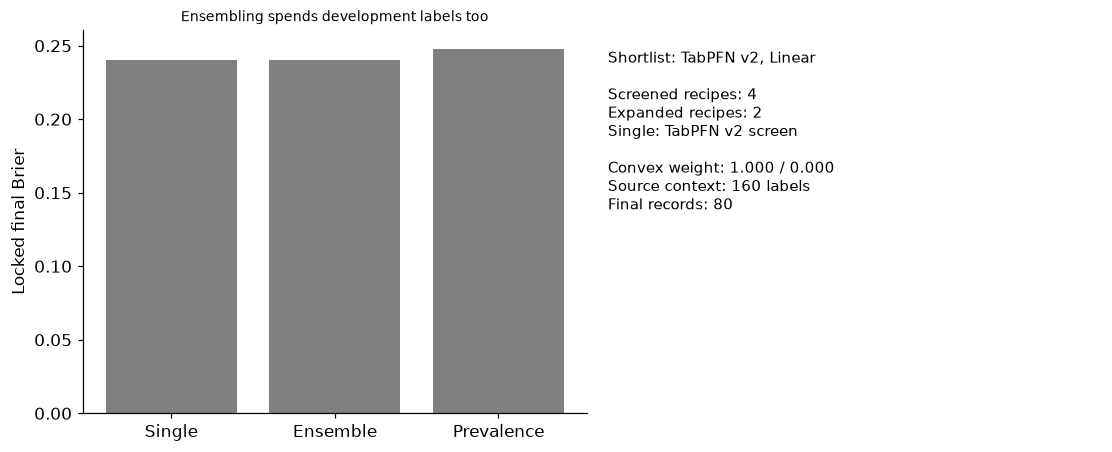

In [3]:
for family in shortlist:
    predict,detail=fit_family(family,expanded=True);p=predict(X[development]);name=family+' expanded';models[name]=predict;dev_predictions[name]=p;rows.append({'candidate':name,'family':family,'stage':'expanded','development_Brier':float(brier_score_loss(Y[development],p)),'configuration':detail})
ranked=sorted(rows,key=lambda r:r['development_Brier']);selected=ranked[0]['candidate'];members=[r['candidate'] for r in ranked[:2]];a,b=[dev_predictions[n] for n in members];difference=a-b;den=float(difference@difference);w=float(np.clip((difference@(Y[development]-b))/den,0,1)) if den>0 else .5;single=models[selected](X[final]);pa,pb=[models[n](X[final]) for n in members];ensemble=w*pa+(1-w)*pb;baseline=np.repeat(float(Y[source].mean()),int(final.sum()));assessments=[]
for name,p in [('Selected single',single),('Development ensemble',ensemble),('Source prevalence',baseline)]:assessments.append({'method':name,'final_Brier':float(brier_score_loss(Y[final],p)),'final_log_loss':float(log_loss(Y[final],np.c_[1-p,p],labels=[0,1]))})
assert len(rows)==6 and len(models)==6 and 0<=w<=1;assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==expected_hash and len(foundation_hashes)>=1
RESULTS.update(all_attempts=rows,selected_single=selected,ensemble_members=members,ensemble_weight_first=w,ensemble_weights_fit_role='development only',final_assessments=assessments,final_used_for_selection=False,pretrained_weights_unchanged=True)
display(pd.DataFrame([{k:v for k,v in r.items() if k!='configuration'} for r in rows]));display(pd.DataFrame(assessments));fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['final_Brier'] for r in assessments],color='.5');axes[0].set(xticks=range(3),xticklabels=['Single','Ensemble','Prevalence'],ylabel='Locked final Brier',title='Ensembling spends development labels too');axes[1].axis('off');axes[1].text(.02,.95,f'Shortlist: {", ".join(shortlist)}\n\nScreened recipes: 4\nExpanded recipes: 2\nSingle: {selected}\n\nConvex weight: {w:.3f} / {1-w:.3f}\nSource context: 160 labels\nFinal records: 80',va='top',fontsize=10);plt.show()


In [4]:
summary={'example_id':'code_185','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual linear tree neural and pinned TabPFN v2 family screening', 'conditional shortlist tuning of representations and architectures', 'source-only learned preprocessing and frozen pretrained weights', 'actual development-fitted convex ensemble with locked final assessment', 'explicit immutable external checkpoint verification and offline inference'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual linear tree neural and pinned TabPFN v2 family screening", "conditional shortlist tuning of representations and architectures", "source-only learned preprocessing and frozen pretrained weights", "actual development-fitted convex ensemble with locked final assessment", "explicit immutable external checkpoint verification and offline inference"], "elapsed_seconds": 2.171, "example_id": "code_185", "hardware": "Darwin arm64 CPU", "results": {"all_attempts": [{"candidate": "Linear screen", "configuration": {"C": 1.0, "representation": "raw four fields"}, "development_Brier": 0.20238735495223076, "family": "Linear", "stage": "screen"}, {"candidate": "Tree screen", "configuration": {"leaves": 7, "trees": 60}, "development_Brier": 0.21244039618082025, "family": "Tree", "stage": "screen"}, {"candidate": "Neural screen", "configuration": {"architecture": [4, 8, 1], "updates": 200, "weights": 49}, "development_Brier": 0.256309152710877, "